# PULSE-A Minute-Level Orbit Analysis (real orbit lengths)

Updated to the **new_mission_power_simulation** engine. The old version folded every orbit onto a fixed 90-minute grid with 35 min eclipse;
this version uses the real STK orbit boundaries (`OrbitNumberBounded`), the real `dt` and the real shadow flag, so every orbit keeps its own length (≈93 min) and its own eclipse (17–37 min).

In [1]:
from __future__ import annotations

import importlib
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# ==========================================
# 0. PATH SETUP
# ==========================================
# Run this notebook from the "PULSE-A Timestep Sim" folder. Data files and
# Basic PB Calculator.py are found automatically in this folder or the parent
# "Orbital Power Budget Sim" folder (including _ORGANIZED/...).
# The engine (new_mission_power_simulation.py) is the importable version of
# new_mission_power_simulation.ipynb - same functions, same equations.
root = Path.cwd()
sys.path.insert(0, str(root))
import new_mission_power_simulation as sim
importlib.reload(sim)          # pick up edits to the engine without restarting

profile_min = sim.find_data_file("PULSEPowerMinE")
profile_max = sim.find_data_file("PULSEPowerMaxE")
power_budget_file = sim.find_power_budget_file()
fig_dir = sim.OUTPUT_DIR / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)

print("root               :", root)
print("power-budget model :", power_budget_file)
print("MinE profile       :", profile_min)
print("MaxE profile       :", profile_max)
print("outputs            :", sim.OUTPUT_DIR)


root               : /sessions/elegant-gifted-newton/mnt/Orbital Power Budget Sim/PULSE-A Timestep Sim
power-budget model : /sessions/elegant-gifted-newton/mnt/Orbital Power Budget Sim/Basic PB Calculator.py
MinE profile       : /sessions/elegant-gifted-newton/mnt/Orbital Power Budget Sim/_ORGANIZED/1_IMPORTANT/data/stk_power_v2_download_from_drive/PULSEPowerMinE (1).csv
MaxE profile       : /sessions/elegant-gifted-newton/mnt/Orbital Power Budget Sim/_ORGANIZED/1_IMPORTANT/data/stk_power_v2_download_from_drive/PULSEPowerMaxE (1).csv
outputs            : /sessions/elegant-gifted-newton/mnt/Orbital Power Budget Sim/PULSE-A Timestep Sim/sim_outputs


In [2]:
state_powers = sim.get_state_powers(power_budget_file)
d = sim.load_case("PULSEPowerMinE", profile_min, "MinTotalPower")
sim.add_orbit_clock(d)
sim.print_validation_report(sim.validate_profile(d), "PULSEPowerMinE")

battery_capacity_wh = sim.BATTERY_CAPACITY_WH
load_power_w = 9.10                      # master-budget orbit-average load (conservative)
representative_initial_soc_wh = 12.0     # low-SoC start used in the original fixviz study (30 %)


Validation report PULSEPowerMinE
------------------------------------------------------------
rows / span                 : 1,051,207 rows over 730.00 days
first elapsed minutes       : [0.     0.5    0.9999 1.5    2.    ]
first dt minutes            : [0.5    0.5    0.5001 0.5    0.5   ]
dt median / min / max (min) : 0.9999 / 0.5000 / 1.0001
irregular timesteps         : 15  (first rows [0 1 2 3 4 5 6 7 8 9])
missing (NaN) values        : 0   non-positive dt: 0
shadow values present       : [0. 1.]  unexpected: 0
orbit number decreases/skips: 0 / 0
generation profile type     : cumulative
negative generation steps   : 0 (larger than noise: 0)
generation in sunlight      : 212810.5 Wh
generation in eclipse       : 1494.4 Wh (0.70 % of total; shadow-boundary samples / penumbra)
mean power sunlit / eclipse : 18.86 W / 0.240 W
energy units look suspicious: False



## Real orbit durations from the orbit-number column

In [3]:
# Replaces the manual loop of the old notebook: orbit length = sum of dt per orbit number.
r_base = sim.run_csv_mission_simulation("PULSEPowerMinE", csv_data=d, state_powers=state_powers)
summary = sim.summarize_by_orbit(r_base)
flags = sim.orbit_flags(summary)
print("first 20 orbit ids:", summary[:20, 0].astype(int))
print("first 10 durations (min):", np.round(summary[:10, 1], 3))
print(f"partial orbits flagged: {summary[flags['partial'], 0].astype(int)} "
      f"(durations {np.round(summary[flags['partial'], 1], 1)} min)")
full = summary[flags["full"]]
print(f"full orbits: {len(full)}; duration mean {full[:,1].mean():.3f} min, min {full[:,1].min():.2f}, max {full[:,1].max():.2f}")


first 20 orbit ids: [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20]
first 10 durations (min): [11.667 93.    94.    93.    93.    94.    93.    93.    93.    94.   ]
partial orbits flagged: [    1 11270] (durations [11.7 40. ] min)
full orbits: 11268; duration mean 93.286 min, min 93.00, max 94.00


## Build per-orbit traces on each orbit's own time axis

In [4]:
orbit = d["orbit_number"]
starts = np.r_[0, np.where(np.diff(orbit) != 0)[0] + 1]
ends = np.r_[starts[1:], len(orbit)]
full_ids = set(full[:, 0].astype(int))

def orbit_trace(orbit_id):
    """minute-in-orbit, generation power (W), shadow flag, dt (h) for one orbit."""
    k = int(np.where(orbit[starts] == orbit_id)[0][0])
    sl = slice(starts[k], ends[k])
    return d["minute_in_orbit"][sl], d["generation_w"][sl], d["in_shadow"][sl], d["dt_hours"][sl]

def soc_through_orbit(orbit_id, initial_soc_wh, load_w):
    """Intra-orbit SoC with E = (P_gen - P_load) * dt on the REAL timestep."""
    m, p, sh, dt = orbit_trace(orbit_id)
    soc = np.empty(len(m) + 1); soc[0] = initial_soc_wh
    cap = battery_capacity_wh * sim.MAX_SOC_FRACTION
    for i in range(len(m)):
        soc[i + 1] = min(cap, max(0.0, soc[i] + (p[i] - load_w) * dt[i]))
    return np.r_[m, m[-1] + dt[-1] * 60], soc

gen = full[:, sim.COL["generation_wh"]]; ecl = full[:, sim.COL["eclipse_min"]]
picks = {
    "median generation": int(full[np.argsort(gen)[len(gen) // 2], 0]),
    "lowest generation": int(full[np.argmin(gen), 0]),
    "longest eclipse": int(full[np.argmax(ecl), 0]),
    "shortest eclipse": int(full[np.argmin(ecl), 0]),
}
for k, oid in picks.items():
    row = full[full[:, 0] == oid][0]
    print(f"{k:<18} orbit {oid:>6}: duration {row[1]:.1f} min, eclipse {row[2]:.0f} min, generation {row[4]:.2f} Wh")


median generation  orbit   3864: duration 94.0 min, eclipse 36 min, generation 18.73 Wh
lowest generation  orbit   7206: duration 93.0 min, eclipse 37 min, generation 17.45 Wh
longest eclipse    orbit   8334: duration 94.0 min, eclipse 37 min, generation 17.74 Wh
shortest eclipse   orbit   2020: duration 93.0 min, eclipse 17 min, generation 23.08 Wh


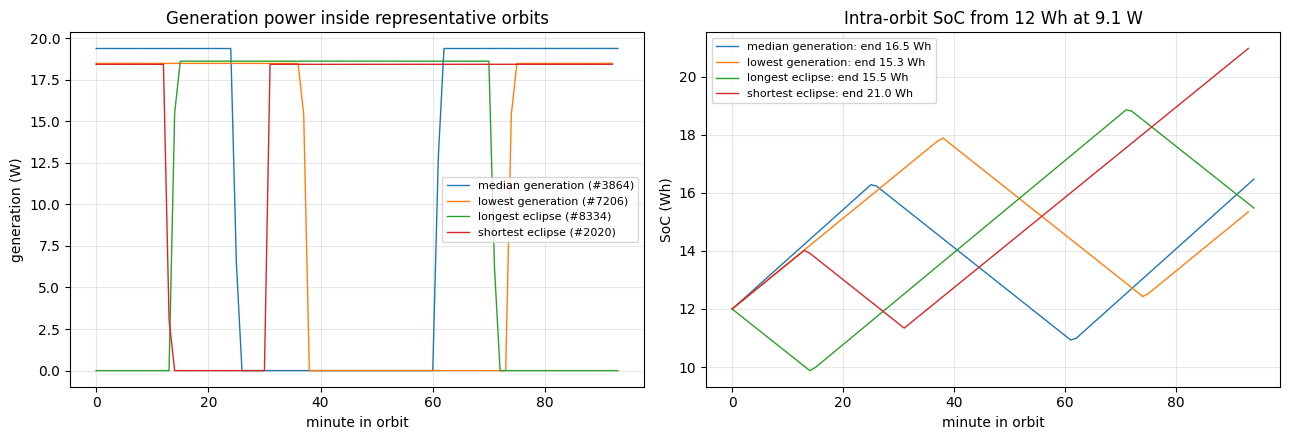

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for k, oid in picks.items():
    m, p, sh, dt = orbit_trace(oid)
    axes[0].plot(m, p, lw=1, label=f"{k} (#{oid})")
    t, soc = soc_through_orbit(oid, representative_initial_soc_wh, load_power_w)
    axes[1].plot(t, soc, lw=1, label=f"{k}: end {soc[-1]:.1f} Wh")
axes[0].set_xlabel("minute in orbit"); axes[0].set_ylabel("generation (W)"); axes[0].grid(alpha=0.3); axes[0].legend(fontsize=8)
axes[0].set_title("Generation power inside representative orbits")
axes[1].set_xlabel("minute in orbit"); axes[1].set_ylabel("SoC (Wh)"); axes[1].grid(alpha=0.3); axes[1].legend(fontsize=8)
axes[1].set_title(f"Intra-orbit SoC from {representative_initial_soc_wh:.0f} Wh at {load_power_w} W")
plt.tight_layout(); plt.savefig(fig_dir / "fixviz_representative_orbits.png", dpi=200); plt.show()


## End-of-orbit SoC over orbit sets (low-SoC start, 9.10 W)

In [6]:
def summarize_orbit_set(orbit_ids, initial_soc_wh=representative_initial_soc_wh, load_w=load_power_w):
    end_soc = np.array([soc_through_orbit(o, initial_soc_wh, load_w)[1][-1] for o in orbit_ids])
    min_soc = np.array([soc_through_orbit(o, initial_soc_wh, load_w)[1].min() for o in orbit_ids])
    print(f"[orbits {orbit_ids[0]}-{orbit_ids[-1]}] end SoC mean/std {end_soc.mean():.2f}/{end_soc.std():.2f} Wh, "
          f"lowest in-orbit SoC {min_soc.min():.2f} Wh, any orbit net-negative: {bool((end_soc < initial_soc_wh).any())}")
    return end_soc, min_soc

ids = [int(o) for o in full[:, 0]]
_ = summarize_orbit_set(ids[:50])
_ = summarize_orbit_set(ids[:100])
end_all, min_all = summarize_orbit_set(ids)


[orbits 2-51] end SoC mean/std 17.91/0.24 Wh, lowest in-orbit SoC 11.24 Wh, any orbit net-negative: False
[orbits 2-101] end SoC mean/std 17.50/0.48 Wh, lowest in-orbit SoC 10.18 Wh, any orbit net-negative: False


[orbits 2-11269] end SoC mean/std 16.87/1.32 Wh, lowest in-orbit SoC 6.59 Wh, any orbit net-negative: False


## Eclipse depth of discharge vs eclipse length (whole mission)

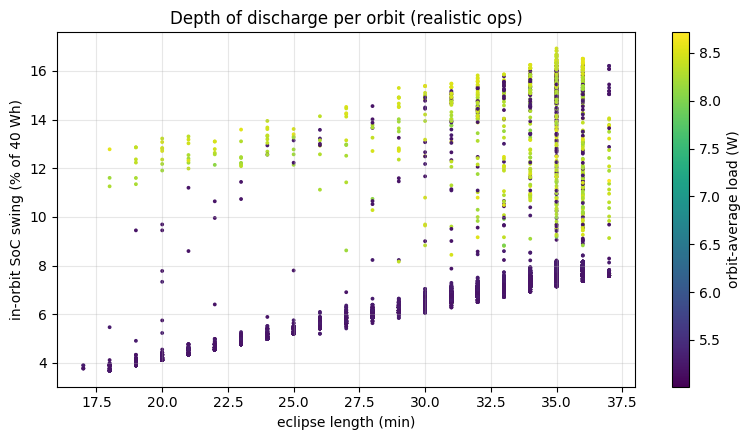

max in-orbit swing 16.9 %  (orbit 4572); median 7.6 %


In [7]:
# Using the realistic-ops timestep run: SoC drop inside each orbit.
r_ops = sim.run_csv_mission_simulation("PULSEPowerMinE", csv_data=d, schedule=sim.OpsSchedule(), state_powers=state_powers)
s_ops = sim.summarize_by_orbit(r_ops); f_ops = sim.orbit_flags(s_ops)["full"]; s_ops = s_ops[f_ops]
dod = s_ops[:, sim.COL["max_soc_percent"]] - s_ops[:, sim.COL["min_soc_percent"]]
fig, ax = plt.subplots(figsize=(8, 4.5))
sc = ax.scatter(s_ops[:, sim.COL["eclipse_min"]], dod, s=3, c=s_ops[:, sim.COL["mean_power_w"]], cmap="viridis")
plt.colorbar(sc, label="orbit-average load (W)")
ax.set_xlabel("eclipse length (min)"); ax.set_ylabel("in-orbit SoC swing (% of 40 Wh)"); ax.grid(alpha=0.3)
ax.set_title("Depth of discharge per orbit (realistic ops)")
plt.tight_layout(); plt.savefig(fig_dir / "fixviz_dod_vs_eclipse.png", dpi=200); plt.show()
print(f"max in-orbit swing {dod.max():.1f} %  (orbit {int(s_ops[np.argmax(dod), 0])}); median {np.median(dod):.1f} %")
